# 延迟运算

In [1]:
import polars as pl
import numpy as np
import threading
from helper.jupyter import row

Polars 的延迟运算(lazy)不会在定义时立即执行，而是先把操作累积成“执行计划”，等 `collect()` 时再一起优化和执行。

这样做有三个好处：

1. 优化器能看到全局，省掉多余的计算并调整顺序。
2. 数据只在真正需要时才被处理，内存占用更低。
3. 面对比内存还大的数据，还能切块流式处理。

这一章先看延迟运算的基本流程，再看流式处理的机制，最后借 UDF 实际确认切块与并行确实发生在运行中。

## 基本流程

延迟运算的写法分三步：

1. 用 `DataFrame.lazy()` 转成 `LazyFrame`，或用 `scan_*()` 直接从文件取得 `LazyFrame`。
2. 搭建过滤、聚合等处理链，这些调用只往计划里加节点，并不执行。
3. 用 `collect()` 执行，或用 `explain()`、`show_graph()` 查看执行计划。

下面的例子先用 `df.lazy()` 转成 `LazyFrame`，再用和 `DataFrame` 同名的方法搭处理链，写法几乎一模一样。

In [2]:
df = pl.DataFrame({
    "product": ["A", "B", "C", "A", "B"],
    "category": ["X", "Y", "X", "Y", "X"],
    "price": [100, 200, 150, 300, 250],
    "quantity": [5, 3, 4, 2, 6]
})

lazy_operations = (
    df.lazy()
    .filter(pl.col("price") > 150)
    .filter(pl.col("price") < 280)
    .group_by("category")
    .agg(pl.col("quantity").sum().alias("total_quantity"))
)

用 `show_graph()` 可以分析执行计划，两次调用的结果可以直接对照。`optimized` 参数给 `True` 时看到的是优化后的计划，对比优化前后就能看出优化器做了什么。

如下面的输出所示，优化后两个 `FILTER` 合并成了一个 `SELECTION`，两个条件被合成一次扫描，数据只读一遍。

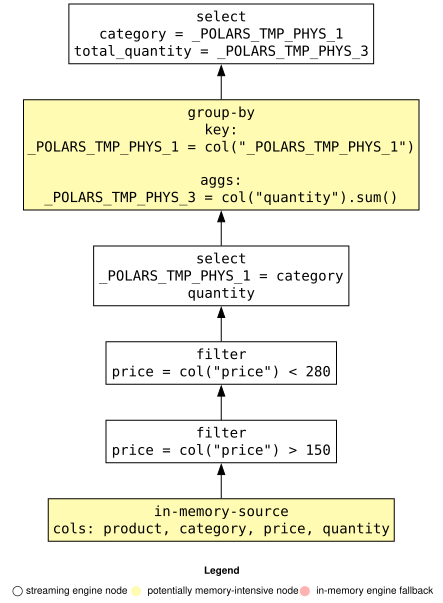

In [3]:
lazy_operations.show_graph(optimized=False)

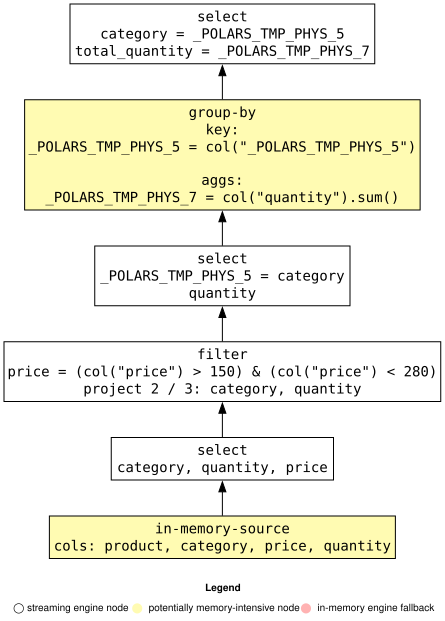

In [4]:
lazy_operations.show_graph(optimized=True)

取运算结果要调用 `collect()`，它才触发执行。在此之前的所有调用都只是在搭计划，所以删掉中间某一步也不会有额外的开销。

In [5]:
lazy_operations.collect()

category,total_quantity
str,i64
"""X""",6
"""Y""",3


`collect()` 执行后处理链仍然保留，所以可以再加 `sort()` 重新执行，不必从头重新搭建。

In [6]:
lazy_operations.sort("total_quantity", descending=True).collect()

category,total_quantity
str,i64
"""X""",6
"""Y""",3


下表整理延迟运算与即时执行的差别，重点是“什么时候真的碰数据”。

| 特征                | 延迟运算 (Lazy)       | 即时执行 (Eager)       |
|---------------------|-----------------------|------------------------|
| 执行时机            | `collect()` 时一次性执行 | 每个操作即时执行     |
| 优化                | 自动进行              | 无                     |
| 内存效率            | 高                    | 低(保留中间结果)     |
| 主要用途            | 大规模数据、复杂处理  | 小规模数据、简单处理   |

流式处理(streaming)用来处理比内存还大的数据：把数据切成称为 chunk(数据块)的小块，逐块处理，只保留当前块的结果，其余部分尽早释放。

这样内存占用只与块的大小有关，而与数据总量无关；代价是某些需要看到全量数据的算子无法流式执行。除此之外，多线程并行仍能保持速度。Polars 2.0 起，`collect()` 默认就走流式引擎。

In [7]:
n = 1000
df = pl.LazyFrame({
    "A": np.random.randn(n),
    "B": np.random.randn(n),
    "C": np.random.randint(0, 10, n)
})

要确认某个运算能不能流式处理，用 `.show_graph(engine="streaming", plan_stage="physical")` 看物理计划。

图里白色节点表示可以流式处理的运算，黄色节点表示能流式处理但可能占用较多内存的运算，红色节点则完全无法流式处理。

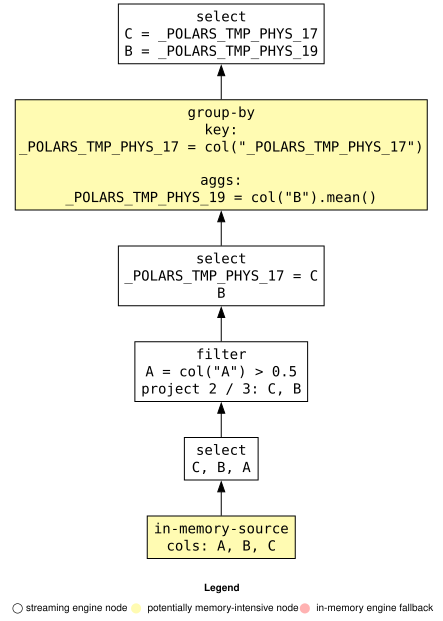

In [8]:
df2 = df.filter(pl.col('A') > 0.5).group_by('C').agg(pl.col('B').mean())
df2.show_graph(engine="streaming", plan_stage="physical")

给 `group_by()` 设了 `maintain_order=True` 时，`group_by()` 的节点会显示成红色，表示无法流式处理，因为要保序就需要把整组数据留在内存里。

这时这个算子会退回 `"in-memory"` 引擎执行。

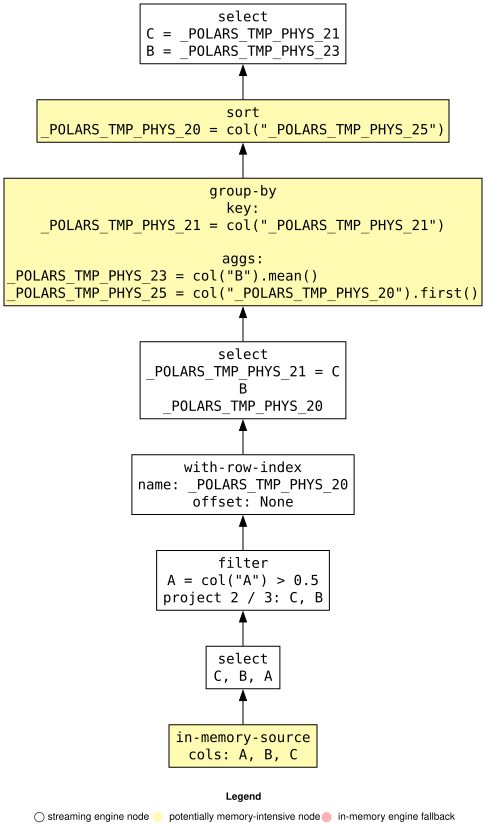

In [9]:
df3 = df.filter(pl.col('A') > 0.5).group_by('C', maintain_order=True).agg(pl.col('B').mean())
df3.show_graph(engine="streaming", plan_stage="physical")

要用流式处理算结果，调 `.collect(engine="streaming")`：能流式的部分走流式，不能的部分退回内存引擎，整体仍然可以算出结果。退回内存引擎的部分不会报错，只是慢一些。

In [10]:
row(df2.collect(engine="streaming"), df3.collect(engine="streaming"))

C,B
i32,f64
4,0.102966
3,0.071591
2,-0.466123
7,-0.168052
8,-0.39633
5,0.231992
6,0.022844
1,0.245642
9,0.374534


## 用 UDF 观察流式处理

想实际确认流式处理确实在切块、在并行，可以借 `map_batches()`、`map_elements()` 这类用户定义函数(UDF)来观察。

在函数里打印数据长度和当前线程，就能看到 Polars 把数据切成了多大的块、分给了哪些线程。

### `Expr.map_batches`

下面的代码做了两件事：用 `threading.Lock()` 防止多个线程的输出混在一起，把 `map_batches()` 的 `is_elementwise` 设为 `True` 来启用切块与并行。

`is_elementwise=True` 是这里的关键，它等于向 Polars 保证“这个函数逐个元素算”，引擎才会把数据切块并行。

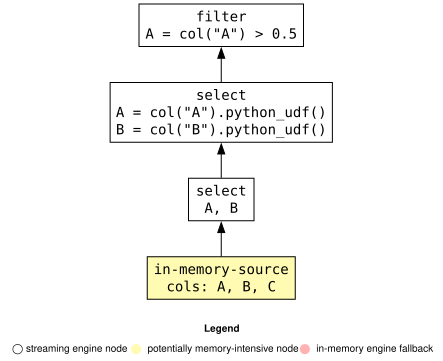

In [11]:
lock = threading.Lock()
def f(s):
    with lock:
        print(s.name, s.shape, threading.current_thread())
        return s

df4 = (
    df
    .select(
        pl.col('A', 'B').map_batches(f, return_dtype=pl.self_dtype(), is_elementwise=True)
    )
    .filter(pl.col('A') > 0.5)
)
df4.show_graph(engine="streaming", plan_stage="physical")

执行 `collect(engine="streaming")` 后，输出显示 A 列和 B 列各被切成长度 125 的 chunk，在不同线程里并行处理。

125 并非随意选定：块的大小由引擎按 CPU 核数切分，所以换个核数不同的机器，这个数字也会变。

In [12]:
df4.collect(engine="streaming");

A (50,) <_DummyThread(Dummy-13, started daemon 20124)>
A (50,) <_DummyThread(Dummy-14, started daemon 37988)>
A (50,) <_DummyThread(Dummy-15, started daemon 25208)>
A (50,) <_DummyThread(Dummy-16, started daemon 20128)>
A (50,) <_DummyThread(Dummy-17, started daemon 27480)>
A (50,) <_DummyThread(Dummy-18, started daemon 37000)>
A (50,) <_DummyThread(Dummy-19, started daemon 3044)>
A (50,) <_DummyThread(Dummy-20, started daemon 26396)>
A (50,) <_DummyThread(Dummy-21, started daemon 34248)>
A (50,) <_DummyThread(Dummy-22, started daemon 9388)>
A (50,) <_DummyThread(Dummy-23, started daemon 30636)>
A (50,) <_DummyThread(Dummy-24, started daemon 17196)>
A (50,) <_DummyThread(Dummy-25, started daemon 28052)>
A (50,) <_DummyThread(Dummy-26, started daemon 23636)>
A (50,) <_DummyThread(Dummy-27, started daemon 24196)>
A (50,) <_DummyThread(Dummy-28, started daemon 35904)>
A (50,) <_DummyThread(Dummy-29, started daemon 22664)>
A (50,) <_DummyThread(Dummy-30, started daemon 34064)>
A (50,) <_Du

而用 `in-memory` 引擎时，A 列和 B 列不会被切块，各自整体在单独的线程里处理，列之间并行，列内部串行。

In [13]:
df4.collect(engine="in-memory");

A (1000,) <_DummyThread(Dummy-53, started daemon 25976)>
B (1000,) <_DummyThread(Dummy-54, started daemon 31112)>


用 `scan_*()` 从文件读数据再处理时，事先不知道数据长度，所以如下面的输出所示，chunk 大小不均匀。

这是流式处理的常态：块的大小由读取时凑齐的数据决定，不能假定每块大小相同。

In [14]:
df.collect().write_csv('data/streaming_test.csv')
df5 = (
    pl
    .scan_csv('data/streaming_test.csv')
    .select(
        pl.col('A', 'B').map_batches(f, return_dtype=pl.self_dtype(), is_elementwise=True)
    )
    .filter(pl.col('A') > 0.5)
)
df5.collect(engine="streaming");

A (1000,) <_DummyThread(Dummy-55, started daemon 25208)>
B (1000,) <_DummyThread(Dummy-56, started daemon 20128)>


### `LazyFrame.map_batches`

`LazyFrame` 的 `map_batches()` 也支持流式处理：把 `streamable` 参数设为 `True` 即可。

这时原始数据会被切成 chunk，每块作为 `DataFrame` 对象传给 UDF，所以函数接收的是“一整块表”，而不是一串行。

In [15]:
lock = threading.Lock()
def f(df):
    with lock:
        print(type(df).__name__, df.shape, threading.current_thread())
        return df

df2 = df.map_batches(f, streamable=True)
df2.collect(engine="streaming");

DataFrame (50, 3) <_DummyThread(Dummy-57, started daemon 18500)>
DataFrame (50, 3) <_DummyThread(Dummy-58, started daemon 35048)>
DataFrame (50, 3) <_DummyThread(Dummy-59, started daemon 8656)>
DataFrame (50, 3) <_DummyThread(Dummy-60, started daemon 22080)>
DataFrame (50, 3) <_DummyThread(Dummy-61, started daemon 24848)>
DataFrame (50, 3) <_DummyThread(Dummy-62, started daemon 12768)>
DataFrame (50, 3) <_DummyThread(Dummy-63, started daemon 16580)>
DataFrame (50, 3) <_DummyThread(Dummy-64, started daemon 16172)>
DataFrame (50, 3) <_DummyThread(Dummy-65, started daemon 488)>
DataFrame (50, 3) <_DummyThread(Dummy-66, started daemon 26096)>
DataFrame (50, 3) <_DummyThread(Dummy-67, started daemon 32772)>
DataFrame (50, 3) <_DummyThread(Dummy-68, started daemon 4432)>
DataFrame (50, 3) <_DummyThread(Dummy-69, started daemon 19624)>
DataFrame (50, 3) <_DummyThread(Dummy-70, started daemon 12160)>
DataFrame (50, 3) <_DummyThread(Dummy-71, started daemon 23264)>
DataFrame (50, 3) <_DummyThre

### `Expr.map_elements`

`map_elements()` 把每个值逐个交给 UDF，再收集结果，用流式引擎时，运算会在多个线程上并行执行。

因为它逐元素调用 Python 函数，开销比 `map_batches()` 大得多，只适合元素级的小逻辑。

In [16]:
lock = threading.Lock()
def f(val):
    with lock:
        print(val, threading.current_thread())
        return val

n = 10

df = pl.LazyFrame({
    "A": np.random.randn(n),
    "B": np.random.randn(n),
    "C": np.random.randint(0, 10, n)
})
        
df2 = df.select(
    pl.col('A', 'B').map_elements(f, return_dtype=pl.self_dtype())
)

In [17]:
df2.collect(engine="streaming");

-0.6312592584694728 <_DummyThread(Dummy-77, started daemon 27480)>
0.21334492760937857 <_DummyThread(Dummy-78, started daemon 26396)>
0.7770442375202342 <_DummyThread(Dummy-79, started daemon 3044)>
-0.30072397464235245 <_DummyThread(Dummy-80, started daemon 34248)>
1.647108956453381 <_DummyThread(Dummy-81, started daemon 9388)>
-1.391253051153269 <_DummyThread(Dummy-82, started daemon 30636)>
0.6249156714023212 <_DummyThread(Dummy-83, started daemon 17196)>
0.30551592777205183 <_DummyThread(Dummy-84, started daemon 28052)>
-0.23249988808965036 <_DummyThread(Dummy-85, started daemon 23636)>
0.8908829206955324 <_DummyThread(Dummy-86, started daemon 37000)>
-0.671752231044049 <_DummyThread(Dummy-87, started daemon 24196)>
-0.14938985868389532 <_DummyThread(Dummy-88, started daemon 35904)>
0.07353565961939337 <_DummyThread(Dummy-89, started daemon 22664)>
0.694506058259588 <_DummyThread(Dummy-90, started daemon 34064)>
-0.18050839234665692 <_DummyThread(Dummy-91, started daemon 10736)>
0.

In [18]:
df2.collect(engine="in-memory");

-0.6312592584694728 <_DummyThread(Dummy-97, started daemon 25976)>
0.8908829206955324 <_DummyThread(Dummy-97, started daemon 25976)>
0.21334492760937857 <_DummyThread(Dummy-97, started daemon 25976)>
0.7770442375202342 <_DummyThread(Dummy-97, started daemon 25976)>
-0.30072397464235245 <_DummyThread(Dummy-97, started daemon 25976)>
-0.23249988808965036 <_DummyThread(Dummy-97, started daemon 25976)>
1.647108956453381 <_DummyThread(Dummy-97, started daemon 25976)>
-1.391253051153269 <_DummyThread(Dummy-97, started daemon 25976)>
0.6249156714023212 <_DummyThread(Dummy-97, started daemon 25976)>
0.30551592777205183 <_DummyThread(Dummy-97, started daemon 25976)>
-0.671752231044049 <_DummyThread(Dummy-98, started daemon 11492)>
0.7256219833863601 <_DummyThread(Dummy-98, started daemon 11492)>
-0.14938985868389532 <_DummyThread(Dummy-98, started daemon 11492)>
0.07353565961939337 <_DummyThread(Dummy-98, started daemon 11492)>
0.694506058259588 <_DummyThread(Dummy-98, started daemon 11492)>
1.